---
format:
  html: default
---

# A5: Poisson's equation and Gauss quadrature {.unnumbered}

Assignment 5: Linear systems (Poisson's equation) and eigenvalue problems (Gauss quadrature) </br>
Published: <b>Nov 23</b>

<div class="alert alert-block alert-info">
<b>Note:</b>
<ul>
  <li>Complete the following and submit to Canvas before <b>7 Dec 23:59</b>.</li>
  <li>Late work will receive 0%.</li>
  <li>Each assignment is worth the same.</li>
  <li><b>This is an individual assignment.</b> I encourage you to discuss the course material and the questions with your classmates, but you must complete and write up your solutions on your own.</li>
  <li>Please get in contact with the TA/instructor in plenty of time if you need help.</li>
  <li>Before submitting your work, make sure to check everything runs as expected. Click <b>Kernel &gt; Restart Kernel and Run All Cells</b>. Submit your notebook in .pdf format by clicking <b>File &gt; Export Notebook As &gt; PDF</b> or by printing to PDF in the browser.</li>
  <li>Feel free to add more cells to experiment or test your answers.</li>
  <li>The use of GenAI is prohibited as outlined in the course syllabus. If I suspect you of cheating, you may be asked to complete a written or oral exam on the content of this assignment.</li>
</ul>
</div>

<div class="custom-lecture-buttons my-3 d-flex gap-2">
  <a href="https://raw.githubusercontent.com/jackrthomas/Math5485/main/assignments/A05.ipynb" class="btn-download-ipynb btn btn-outline-primary btn-sm" target="_blank">
    <i class="bi bi-journal-code"></i> Download (.ipynb)
  </a>
</div>

The assignment is worth **100 pts**: Section A 40 pts, Section B 40 pts and Section C (reflection) 20 pts. The symbols ✍️, 💻 indicate theory ($\LaTeX$), practice (code), respectively.

In this assignment we see two ways in which *linear algebra* enters numerical analysis. In Section A, the discretisation of a differential equation (Poisson's equation) gives a large linear system $A \mathbf c = \mathbf b$, and we study what Julia does to solve it. In Section B, the zeros of the Legendre polynomials (the nodes of Gaussian quadrature) are found as the eigenvalues of a matrix: a motivation for eigenvalue problems.

The following cell loads the packages and defines ```gauss_ref(n)```, which returns the nodes and weights of the $n$-point Gauss rule on $[-1,1]$ (it uses Newton's method on the Legendre polynomials, not the eigenvalue method of Exercise 4, so you can use it to check your own code).

In [ ]:
# | code-fold: true

using Plots, LaTeXStrings, LinearAlgebra, Polynomials, Printf
using Random
Random.seed!(1)

# n-point Gauss-Legendre rule on [-1,1]: returns (nodes, weights). (Newton's method on P_n, evaluated by
# the three-term recurrence; standard normalisation P_n(1) = 1.)
function gauss_ref(n)
    x = zeros(n); w = zeros(n)
    for i ∈ 1:n
        z = cos(π * (i - 0.25) / (n + 0.5))
        dp = 0.0
        for _ ∈ 1:100
            p1, p2 = 1.0, 0.0
            for k ∈ 1:n
                p3 = p2; p2 = p1
                p1 = ((2k - 1) * z * p2 - (k - 1) * p3) / k
            end
            dp = n * (z * p1 - p2) / (z^2 - 1)
            dz = p1 / dp
            z -= dz
            abs(dz) < 1e-15 && break
        end
        x[i] = z
        w[i] = 2 / ((1 - z^2) * dp^2)
    end
    return reverse(x), reverse(w)
end;

## A: Poisson's equation [40 pts] {.unnumbered}

Chapter 5 is about solving linear systems of equations $A x = b$. In this section, we see what Julia actually does when you type ```A \ b``` and how the discretisation of differential equations leads to large linear systems of equations.

### What does ```A \ b``` do?

Julia does not compute the inverse $A^{-1}$ and multiply. For a square matrix $A$, the command ```A \ b``` chooses a method according to the type of $A$ and solves the system with a matrix factorisation:

* If $A$ is upper or lower triangular: backward or forward substitution, no factorisation needed ($O(n^2)$ operations),
* If $A$ is a general dense matrix: an $LU$ decomposition with pivoting, $PA = LU$ (see Lecture 14), followed by two triangular solves $L y = P b$ and $U x = y$. The factorisation uses $O( n^3 )$ operations and each triangular solve about $O(n^2)$,
* If $A$ is stored as a special type such as ```Tridiagonal``` (or a *sparse* matrix): specialised algorithms which take advantage of the zeros, e.g. $O(n)$ operations for a tridiagonal matrix.

(Other factorisations are available: e.g. the Cholesky decomposition $A = R^\top R$ for symmetric positive definite matrices.) 

You can see the factorisation explicitly by doing ```F = lu(A)``` and access $L, U, P$ with ```F.L```, ```F.U```, and ```F.p```. Check that $PA = LU$ (up to floating point) with ```A[F.p, :] ≈ F.L * F.U```.

***Exercise 1. (What does ```A \ b``` do?)***

(i) 💻 [4 pts] Let ```A = rand(6, 6)``` and ```b = rand(6)```. Compute ```F = lu(A)``` and check that ```A[F.p, :]``` equals ```F.L * F.U``` up to rounding. Then solve $A x = b$ using the (P)LU decomposition and check your answer agrees with ```A \ b```.

Hint: use e.g ```y = LowerTriangular(F.L) \ b[F.p]```. Here, ```b[F.p]``` is $P b$.

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

In [ ]:
A = rand(6, 6); b = rand(6);

# your code here

(ii) ✍️💻 [3 pts] Suppose you need to solve $A \mathbf x^{(k)} = \mathbf b^{(k)}$ for $m$ different right hand sides $\mathbf b^{(1)}, \dots, \mathbf b^{(m)}$ with the same matrix $A \in \mathbb R^{n\times n}$. Compare the time it takes to call ```A \ b``` $m$ times (for each $\mathbf b^{(k)}$) and finding the (P)LU decomposition of $A$ once and doing forwards and backwards substitution $m$ times. Some of the code has been provided for you.

In [ ]:
n, m = 1000, 50
A = rand(n, n)
bs = [rand(n) for _ ∈ 1:m]

# approach 1: solve A x = b from scratch for each right hand side
s = @elapsed begin
    for b ∈ bs
        x = A \ b
    end
end

# approach 2: factorize A once, then reuse the factorization for each b
t = @elapsed begin
    F = lu(A)
    for b ∈ bs
        
        # your code here

    end
end

println("A \\ b each time: $(round(s, digits=3)) s")
println("factorize once:  $(round(t, digits=3)) s")
println("ratio s/t:       $(round(s/t, digits=1))")

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

(iii) 💻✍️ [3 pts] Here, we compute the solution to $T x = b$ for a tridiagonal matrix $T$ in two ways. Explain why the first is quicker.

In [58]:
n = 2500
T = Tridiagonal(-ones(n-1), 2ones(n), -ones(n-1))
b = rand(n)

s = @elapsed begin
    T \ b
end

t = @elapsed begin 
    Matrix(T) \ b 
end

s, t, t/s

(0.0001225, 0.4515476, 3686.1028571428574)

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

<div style="break-after: page;"></div>

### Poisson's equation

For a fixed *forcing* $f:[-1,1] \to \mathbb R$, we consider *Poisson's equation with Dirichlet boundary conditions*:

\begin{align}
    -u''(x) &= f(x) \\
    u(-1) &= u_- \\
    u(+1) &= u_+.
\end{align}

(Poisson's equation in dimension $d$ is given by $- \Delta u := - \sum_{i=1}^d \frac{\partial^2u}{\partial x_i^2} = f$. Here, $\Delta$ is the Laplacian and $-\Delta u = 0$ is known as Laplace's equation.)

This equation appears in different areas of applied math and engineering. For example,

* Heat conduction: $u$ models the equilibrium temperature on a rod $[-1,1]$ given internal sources of heat $f$,
* Electrostatics: $u$ is the electrostatic potential given a charge density $f$,
* Elastic deformation: $u$ is the displacement of a beam (or a string) under external forces $f$,
* Newton's law of gravitation, and so on.

The boundary condition states that, e.g., the temperature at the edge of the rod is fixed and equal to $u_{\pm}$. In the following questions we will solve this boundary value problem numerically in the case that $u_- = u_+ = 0$. This will lead to a *sparse* linear system $A \mathbf c = \mathbf b$ of the kind discussed in Exercise 1.

***Exercise 2.***

(i) ✍️ [2 pts] Suppose that $\{\phi_{j}\}_{j=1}^{n-1}$ is a set of functions satisfying the boundary conditions $\phi_j(-1) = \phi_j(1) = 0$. Show that $u(x) = \sum_{j=1}^{n-1} c_j \phi_j(x)$ satisfies the boundary conditions $u(-1) = u(1) = 0$ for any choice of coefficients $\{c_j\}$.

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

(ii) ✍️ [5 pts] Show that if we assume $u = \sum_{j=1}^{n-1} c_j \phi_j$ solves the differential equation $-u'' = f$, then
\begin{align}
    \sum_{j=1}^{n-1} \int_{-1}^1 \phi_i'(x) \phi_j'(x) \mathrm{d}x \,\, c_j
    %
    &= \int_{-1}^1 \phi_i(x)  f(x) \mathrm{d}x
\end{align}
for all $i = 1,2, \dots, n-1$. *Hint:* multiply $-u'' = f$ by $\phi_i$ and integrate (this is known as a *weak formulation* of the problem).

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

Notice that this equation can be written as $A \mathbf c = \mathbf b$ with

\begin{align}
    A_{ij} &:= \int_{-1}^{+1} \phi_i'(x) \phi_j'(x) \mathrm{d}x, \\
    %
    b_i &:= \int_{-1}^{+1} \phi_i(x) f(x) \mathrm{d}x.
\end{align}

We may therefore approximate the solution of Poisson's equation by solving $A \mathbf c = \mathbf b$ (with ```A \ b```, see above) and expanding $u(x) = \sum_{j=1}^{n-1} c_j \phi_j(x)$. 

### Hat functions

Fix $X = \{x_0< \dots< x_n\}$ to be the set of equispaced points on $[-1,1]$ with $x_0= -1$ and $x_n = 1$ and notice that $x_{i+1}-x_i = h := \frac{2}{n}$. Consider the *hat functions* $h_j$ defined as the functions that are linear in the intervals $[x_i, x_{i+1}]$ for all $i$ and such that $h_j(x_j) = 1$ and $h_j(x_i) = 0$ for all $i \not= j$. Here, we plot two of these functions:

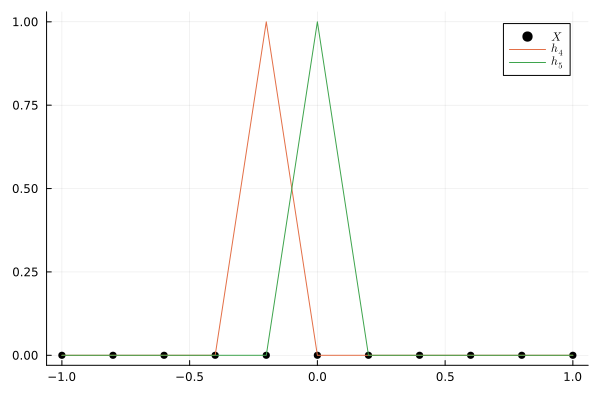

In [5]:
n = 10;
X = -1:(2/n):1

scatter( X, zeros(n+1), label=L"X", color="black" )
plot!( [X[1],X[4], X[5], X[6], X[n+1]], [0, 0, 1, 0, 0], label=L"h_{4}")
plot!( [X[1], X[5], X[6], X[7], X[n+1]], [0, 0, 1, 0, 0], label=L"h_{5}")

(iii) ✍️ [4 pts] Show that, for $i = 1, \dots, n-1$,
\begin{align}
    h_i(x) &=
    \frac{n}{2}\begin{cases}
        x - x_{i-1} & \text{if } x \in [x_{i-1}, x_i]\\
        %
        x_{i+1} - x & \text{if } x \in [x_{i}, x_{i+1}]\\
        %
        0 &\text{otherwise.}
    \end{cases}
\end{align}
Deduce that $h_i(x) = \max\{0, 1 - |x - x_i|/h\}$.

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

(iv) ✍️ [4 pts] Let $A_{ij} := \int_{-1}^1 h_i'(x) h_j'(x) \,\mathrm{d}x$ for the hat function basis $\{ h_j \}_{j=1}^{n-1}$. Explain why $A_{ij} = 0$ whenever $|i - j| \geq 2$, so that $A$ is *tridiagonal*.

*Hint:* on which interval is $h_i$ non-zero? 

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

Computing the remaining entries (by (iii), $h_i' = \frac1h$ on $(x_{i-1}, x_i)$ and $h_i' = -\frac1h$ on $(x_i, x_{i+1})$) gives $A_{ii} = \frac2h$ and $A_{i,i\pm1} = -\frac1h$, that is,
\begin{align}
    A &= \frac{n}{2}
    \begin{pmatrix}
        2 & -1 & \\
        -1 & 2 & -1 \\
        & -1 & 2 & \ddots \\
        & & \ddots &\ddots &  -1 \\
        & & & -1 & 2
    \end{pmatrix} \in \mathbb R^{(n-1) \times (n-1)}
\end{align}
$A$ is known as a (scaled) discrete Laplacian, $A = \frac{1}{h} \mathrm{tridiag}(-1, 2, -1)$.

So, for a general forcing $f$, the hat function method reads: 

- build the tridiagonal matrix $A$ above, 
- compute
$$
\begin{align}
    b_i &= \int_{-1}^{+1} h_i(x) f(x) \mathrm{d}x 
    \nonumber\\
    &= \int_{x_{i-1}}^{x_{i+1}} h_i(x) f(x) \mathrm{d}x,
\end{align}
$$
- solve $A \mathbf c = \mathbf b$, and 
- set $u_n := \sum_{j=1}^{n-1} c_j h_j$, the piecewise linear function with $u_n(x_j) = c_j$.

### A step forcing

We now apply this to a particular forcing: 
$$
\begin{align}
    f(x) = \begin{cases}
        0 & \text{if } x < \frac13,\\
        %
        1 & \text{if } x \geq \frac13.
    \end{cases}
\end{align}
$$

Substituting this into the weak formulation gives 
$$
\begin{align}
    b_i = \int_{-1}^{+1} \phi_i(x) f(x) \,\mathrm{d}x 
    %
    = \int_{\frac13}^{1} \phi_i(x) \,\mathrm{d}x.
\end{align}
$$

(v) ✍️ [4 pts] Let 
\begin{align}
    U(x) = \begin{cases}
        \frac19 (1 + x) & \text{if } x \leq \frac13,\\
        %
        \frac19 (1 + x) - \frac12 (x - \frac13)^2 & \text{if } x \geq \frac13.
    \end{cases}
\end{align}
Show that $U(-1) = U(1) = 0$ and that $-U''(x) = f(x)$ for $x \not= \frac13$. 

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

Therefore, for every piecewise smooth function $\phi$ with $\phi(-1) = \phi(1) = 0$, we have
\begin{align}
    \int_{-1}^{+1} U'(x) \phi'(x) \mathrm{d}x = \int_{\frac13}^{1} \phi(x) \,\mathrm{d}x.
\end{align}
As a result, $U$ satisfies the weak formulation of $-u'' = f$. We can use this closed form to analyse the error of our approximation schemes.

(vi) 💻 [5 pts] Solve $A \mathbf c = \mathbf b$ for $n = 10$ and plot the piecewise linear function $u_n(x) = \sum_{j=1}^{n-1} c_j h_j(x)$ together with the exact solution $U$. Do the same for $n=10^5$ (the code also prints the time taken to solve the system for $n = 10^5$).

Notice: On writing $\frac13 = x_k + \theta h$ with $\theta \in [0,1)$, the following code sample uses the fact that
\begin{align}
    b_i = \begin{cases}
        0 & \text{if } i \leq k-1,\\
        \frac{h}{2} (1 - \theta)^2 & \text{if } i = k,\\
        h \big(1 - \frac{\theta^2}{2}\big) & \text{if } i = k+1,\\
        h & \text{if } i \geq k+2.
    \end{cases}
\end{align}

In [ ]:
f_step(x) = x ≥ 1/3 ? 1.0 : 0.0                    # forcing 
U(x) = (1/9) * (1 + x) - max(0, x - 1/3)^2 / 2     # exact solution

# interior nodes X = (x_1, ..., x_{n-1}) and the right hand side b
function step_rhs(n)
    h = 2 / n
    X = -1 .+ h .* (1:n-1)
    k = floor(Int, (1/3 + 1) / h)  # x_k ≤ 1/3 < x_{k+1}
    θ = (1/3 - (-1 + k * h)) / h
    b = [X[i] - h > 1/3 ? h : 0.0 for i ∈ 1:n-1]  # h if i ≥ k+2, 0 if i ≤ k-1
    b[k] = h * (1 - θ)^2 / 2
    b[k+1] = h * (1 - θ^2 / 2)
    return X, b
end

function poisson_hat(n)
    h = 2 / n
    X, b = step_rhs(n)

    # your code here: 
    # build A as a Tridiagonal matrix and solve A c = b
    
    return X, c
end

X, c = poisson_hat(10)
plot(U, -1, 1; label="exact solution", lw=2)
scatter!([-1; X; 1], [0; c; 0]; label="hat functions, n = 10", color="black")
plot!([-1; X; 1], [0; c; 0]; color="black", label=false) |> display

X, c = poisson_hat(10^5)
plot(U, -1, 1; label="exact solution", lw=2)
plot!([-1; X; 1], [0; c; 0]; color="black", linestyle=:dash, label=L"hat functions, $n = 10^5$") |> display

println("n = 10^5: ", @elapsed(poisson_hat(10^5)), " s")

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

(vii) ✍️ [6 pts] Let $U_h := \sum_{j=1}^{n-1} U(x_j) h_j$ be the piecewise linear interpolant of $U$ at the nodes. 

(a) The code below computes $\max_i |c_i - U(x_i)|$ for $n = 10, 10^2, 10^3, 10^4$: what do you observe? 

(b) Show that $\int_{-1}^{1} (U - U_h)' h_i' \,\mathrm{d}x = 0$ for each $i$. Hint: $h_i'$ is constant on each interval $[x_k, x_{k+1}]$.

(c) Deduce that $A \mathbf U = \mathbf b$ for $\mathbf U := (U(x_j))_{j=1}^{n-1}$, and conclude that $c_j = U(x_j)$ for all $j$.

(d) Why are the computed errors not exactly zero, and why do they grow with $n$?

In [7]:
# max_i |c_i - U(x_i)|: the error of the hat function method at the nodes
for n ∈ (10, 100, 10^3, 10^4)
    X, c = poisson_hat(n)
    @printf("n = %5d   max |c_i - U(x_i)| = %.2e\n", n, maximum(abs.(c .- U.(X))))
end

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

By (vii), $u_n$ is the piecewise linear interpolant of $U$. Therefore, one obtains
$$
\begin{align}
    \mathrm{err}_n &:= \max_{x \in [-1,1]} |u_n(x) - U(x)| 
    %
    \nonumber\\
    %
    &= \frac{h^2}{8} = \frac{1}{2n^2},
\end{align}
$$
that is, *second order* convergence. Indeed, $U$ is linear on $[-1, \frac13]$, so $u_n = U$ on every interval $[x_i, x_{i+1}]$ to the left of $\frac13$. On each interval $[x_i, x_{i+1}]$ to the right of $\frac13$, the error $U - u_n$ vanishes at $x_i$ and $x_{i+1}$ and has second derivative $U'' = -1$, so it is the quadratic $\frac12 (x - x_i)(x_{i+1} - x)$, whose maximum (at the midpoint) is $\frac{h^2}{8}$. This is the error estimate $\max |U - U_h| \leq \frac{h^2}{8} \| U'' \|_\infty$ for piecewise linear interpolation, which follows from the interpolation error formula of Lecture 6.

Hat functions are *local*: each $h_j$ is non-zero on two intervals only, so $A$ is sparse (tridiagonal, a system we can solve in $O(n)$ operations, see Exercise 1). This also allows one to put more nodes where the solution is not smooth. Global polynomial bases are great for smooth solutions, but they lose their exponential rate of convergence as soon as the solution is not smooth. Choosing a basis of piecewise polynomials on a mesh in this way is the basis of finite element methods (FEM). We will study the finite element method next semester.

<div style="break-after: page;"></div>

## B: Gauss quadrature and eigenvalue problems [40 pts] {.unnumbered}

Throughout this section we write

$$
\begin{align*}
    (f, g) := \int_{-1}^{+1} f(x) g(x) \,\mathrm{d}x, \qquad \|f\|^2 := (f,f),
\end{align*}
$$

for the $L^2$ inner product on $[-1,1]$, $\mathcal P_n$ for the polynomials of degree at most $n$, and $P_n$ for the monic Legendre polynomial of degree $n$ (Lecture 12).

$P_n$ is the monic polynomial of degree exactly $n$ such that $(P_n, P_m) = 0$ for all $m\not=n$. In lectures we saw that $P_0 = 1$, $P_1 = x$ and
\begin{align}
    P_{n+1}(x) = (x - a_n) P_{n}(x) - b_n P_{n-1}(x)
\end{align}
for all $n \geq 1$ where $a_n := \frac{(x P_n, P_n)}{\|P_n\|^2}$ and $b_{n} := \frac{(x P_n, P_{n-1})}{\|P_{n-1}\|^2}$. 

We are interested in computing the zeros of $P_n$ in order to define Gauss quadrature rules: 
\begin{align}
    \int_{-1}^1 f \approx \sum_{j=0}^n w_j f(x_j)
\end{align}
where $x_0, \dots, x_n$ are the zeros of $P_{n+1}$ and the weights are $w_j = \int_{-1}^1 \ell_j(x) \mathrm{d}x$. 

This rule is exact for all polynomials of degree $\leq 2n+1$. The problem is: how to compute the zeros of $P_{n+1}$ for large $n$?

***Exercise 3.***

(i) ✍️ [6 pts] Show that $b_n = \frac{\|P_n\|^2}{\|P_{n-1}\|^2}$.

*Hint:* use the recursion for $P_n$ and the orthogonality of $P_n$ to lower degree polynomials. Treat $n = 1$ separately.

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

This allows us to construct the polynomials $\{P_n\}$ as in the following code. We do this in rational arithmetic (which tracks the coefficients as rational numbers which avoids issues with floating point):

P_3 = -3//5*x + x^3
P_4 = 3//35 - 6//7*x^2 + x^4
 n    a_n      b_n    ‖P_n‖²/‖P_{n-1}‖²
 1   0//1     1//3                 1//3
 2   0//1    4//15                4//15
 3   0//1    9//35                9//35
 4   0//1   16//63               16//63
 5   0//1   25//99               25//99
 6   0//1  36//143              36//143
 7   0//1  49//195              49//195
 8   0//1  64//255              64//255


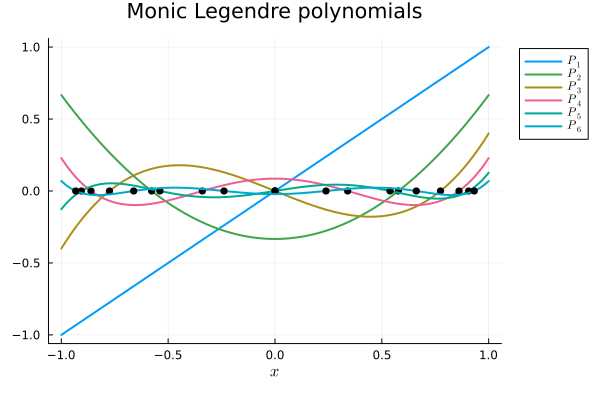

In [10]:
x = Polynomial([0//1, 1//1])
ip(p, q) = (I = integrate(p * q); I(1//1) - I(-1//1))   # (p, q) = ∫_{-1}^{1} p q

P = [Polynomial([1//1]), x]      # P[k+1] is P_k
a = Rational{Int}[]; b = Rational{Int}[]
for n ∈ 1:8
    push!(a, ip(x * P[n+1], P[n+1]) // ip(P[n+1], P[n+1]))
    push!(b, ip(x * P[n+1], P[n]) // ip(P[n], P[n]))
    push!(P, (x - a[n]) * P[n+1] - b[n] * P[n])
end
println("P_3 = ", P[4]); println("P_4 = ", P[5])
@printf("%2s %6s %8s %20s\n", "n", "a_n", "b_n", "‖P_n‖²/‖P_{n-1}‖²")
for n ∈ 1:8
    @printf("%2d %6s %8s %20s\n", n, a[n], b[n], ip(P[n+1], P[n+1]) // ip(P[n], P[n]))
end

plt = plot(; xlabel=L"x", legend=:outertopright, title="Monic Legendre polynomials")
for n ∈ 1:6
    Pf = Polynomial(Float64.(coeffs(P[n+1])))
    plot!(plt, Pf, -1, 1; lw=2, label=latexstring("P_$n"))
    scatter!(plt, sort(real.(roots(Pf))), zeros(n); ms=4, color=:black, label=false)
end
plt

It turns out that $b_n = \frac{n^2}{4n^2 - 1}$ (this can be proved with Rodrigues' formula). In the next two questions, you will prove that $a_{n} = 0$ for all $n$.

(ii) ✍️ [8 pts] Show that $Q(x) := (-1)^n P_n(-x)$ is monic of degree $n$ and orthogonal to all polynomials of degree at most $n-1$. Deduce that $P_n(-x) = (-1)^n P_n(x)$.

*Hint:* make the change of variables $t = -x$ in $(Q, q)$ for $q \in \mathcal P_{n-1}$, and notice that $t \mapsto q(-t)$ is also in $\mathcal P_{n-1}$.

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

(iii) ✍️ [4 pts] Hence show that $x P_n(x)^2$ is an odd function and thus $a_n = 0$ for all $n$. Conclude that $P_{n+1}(x) = x P_n(x) - b_n P_{n-1}(x)$ with $b_n = \frac{\|P_n\|^2}{\|P_{n-1}\|^2}$.

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

<div style="break-after: page;"></div>

***Exercise 4.*** Recall that 
\begin{align}
    P_{n+1}(x) = x P_{n}(x) - b_n P_{n-1}(x)
\end{align}
where $b_n = \frac{n^2}{4n^2 - 1}$.

In [ ]:
N = 40
b = [n^2 / (4n^2 - 1) for n ∈ 1:N]
x = Polynomial([0.0, 1.0])
P = [Polynomial([1.0]), x]
for k ∈ 1:N-1
    push!(P, x * P[k+1] - b[k] * P[k])
end

(i) ✍️ [6 pts] Show that the recursion $P_{k+1}(x) = x P_{k}(x) - b_k P_{k-1}(x)$ can be reformulated as the matrix equation
\begin{align}
    x \begin{pmatrix}
        P_0(x) \\ P_1(x) \\ P_2(x) \\ \vdots \\ P_{n-1}(x) \\ P_n(x)
    \end{pmatrix}
    %
    &=
    T
    \begin{pmatrix}
        P_0(x) \\ P_1(x) \\ P_2(x) \\ \vdots \\ P_{n-1}(x) \\ P_n(x)
    \end{pmatrix}
    %
    + \begin{pmatrix}
        0 \\ 0 \\  \vdots \\ 0 \\ 0 \\ P_{n+1}(x)
    \end{pmatrix}
\end{align}
where $T \in \mathbb R^{(n+1)\times(n+1)}$ is the tridiagonal matrix
\begin{align}
    T = \begin{pmatrix}
        0   & 1   &       \\
        b_1 & 0   & 1     \\
            & b_2 & 0   & 1 \\
            &     & \ddots & \ddots & \ddots \\
            &     &     & b_{n-1} & 0 & 1 \\
            &     &     &       & b_n & 0
    \end{pmatrix}
\end{align}
(the blank entries in this matrix are zeros).

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

(ii) ✍️ [8 pts] Hence show that the zeros of $P_{n+1}$ are eigenvalues of $T$. Why are they *all* of the eigenvalues of $T$?

*Hint:* if $P_{n+1}(x) = 0$, what is $T \mathbf P(x)$ where $\mathbf P(x) := (P_0(x), \dots, P_n(x))^\top$? Why is $\mathbf P(x) \not= \mathbf 0$? How many zeros does $P_{n+1}$ have (recall from Lecture 12 that they are distinct)? How many eigenvalues does $T$ have?

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

It turns out that $T$ has the same eigenvalues as the symmetric tridiagonal matrix
\begin{align}
    T' = \begin{pmatrix}
        0   & \sqrt{b_1}   &       \\
        \sqrt{b_1} & 0   & \sqrt{b_2}     \\
            & \sqrt{b_2} & 0   & \sqrt{b_3} \\
            &     & \ddots & \ddots & \ddots \\
            &     &     & \sqrt{b_{n-1}} & 0 & \sqrt{b_n} \\
            &     &     &       & \sqrt{b_n} & 0
    \end{pmatrix}
\end{align}
and we may compute the zeros of $P_{n+1}$ by computing the eigenvalues of $T'$.

(iii) 💻 [8 pts] For $n = 10, 20, 30, 40$ compute the zeros of $P_n$ with ```roots``` (using the Float64 polynomials ```P``` constructed above) and as the eigenvalues of the symmetric matrix $T'$ of size $n \times n$ (```SymTridiagonal(zeros(n), sqrt.(b[1:n-1]))``` and ```eigvals```). Compare both with ```gauss_ref(n)``` (which uses Newton's method and is accurate to machine precision) and print the maximum errors in a table (the code below does most of this: complete the two lines marked `your code here`). Which method would you use, and why?

<div class='alert alert-block alert-success'><b>Answer.</b> 





</div>

In [ ]:
# maximum errors of the zeros of P_n, computed with roots and as the eigenvalues of T′, against gauss_ref(n)
@printf("%3s %14s %14s\n", "n", "roots", "eig(T′)")
for n ∈ (10, 20, 30, 40)
    xr, _ = gauss_ref(n) # the zeros of P_n using Newton's method

    z_roots = zeros(n)
    # your code here: the zeros of P_n = P[n+1] with roots

    z_eig = zeros(n)                       
    # your code here: the eigenvalues of T′ (n × n) with SymTridiagonal and eigvals
    
    @printf("%3d %14.2e %14.2e\n", n, norm(z_roots - xr, Inf), norm(z_eig - xr, Inf))
end

<div style="break-after: page;"></div>


## C: Reflection [20 pts] {.unnumbered}

**Goal:** Reflect on your learning strategies, track your workload, and help us improve future course material.  
**Time:** take 5-10 mins (this shouldn't take too long)

Estimate the approximate hours you spent:   
* **Assignment:**              ____   
* **Reading notes/materials:** ____    
* **Exercises:**               ____   

(Reminder: you should be spending around 8 hours per week on this course outside of the 4 hours of lectures)

<div class='alert alert-block alert-success'><b>Any other comments:</b> 










</div> 

Take a moment to reflect on your learning over the past few weeks:

What was the easiest topic or task and why? Where did you struggle, and how did you overcome those challenges? Which resources (e.g. lecture notes, practice exercises, peer discussions, ...) helped you the most? How did you manage your time and workload (e.g., all at once, spread out over several days, or working with peers)? Looking back, what would you do differently if you were starting these few weeks over today?

<div class='alert alert-block alert-success'><b>Comments:</b> 










</div> 

(Optional) Any changes that would improve the lectures, exercises, or assignments for the future? You can also suggest things anonymously <a href="http://z.umn.edu/JT-message" 
     class="btn btn-outline-info btn-sm" 
     target="_blank" 
     rel="noopener noreferrer">
    <i class="bi bi-archive me-1" aria-hidden="true"></i>
    here
    <span class="visually-hidden">(opens in a new tab)</span>
  </a> 

<div class='alert alert-block alert-success'><b>Comments:</b> 










</div> 